https://chat.deepseek.com/share/8ejt1f7mx7lkynnss4

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv("train (5).csv")
df_test = pd.read_csv("test (3).csv")

In [3]:
display(df.head())
display(df.describe())
display(df.info())

,id,kode_listing,judul,kategori,jenis_listing,jenis_penawaran,periode_harga,mata_uang,satuan_luas,lokasi_lengkap,...,nama_agen,nama_broker,email_agen,email_broker,email_kontak,telepon_broker,telepon_kontak,whatsapp_kontak,id_broker,harga
0,1,LST014891,Apartment / completed / cash,buy,property,Residential for Sale,sell,EGP,sqm,Z1_0006 / Z2_0004 / Z3_0309 / Z4_0073,...,Person 000300,Person 001945,user002005@example.com,user001943@example.com,user002005@example.com,209000000509,209000000887,209000001719,BRK000161,10000000.0
1,2,LST019439,Apartment / off_plan_primary / installments,buy,property,Residential for Sale,sell,EGP,sqm,Z1_0009 / Z2_0032 / Z3_0054 / Z4_0788,...,Person 001858,Person 000176,user000866@example.com,user000497@example.com,user000866@example.com,209000001858,209000000955,209000001719,BRK000120,6039000.0
2,3,LST007196,Apartment / completed / cash,buy,property,Residential for Sale,sell,EGP,sqm,Z1_0006 / Z2_0004 / Z3_0309 / Z4_0073,...,Person 001125,Person 000308,user000262@example.com,user000262@example.com,user000262@example.com,209000000344,209000001187,209000001719,BRK000107,6000000.0
3,4,LST005496,Villa / completed / installments,buy,property,Residential for Sale,sell,EGP,sqm,Z1_0006 / Z2_0004 / Z3_0309 / Z4_0073,...,Person 002025,Person 000904,user000788@example.com,user000788@example.com,user000788@example.com,209000001965,209000000201,209000001719,BRK000282,42000000.0
4,5,LST017341,Apartment / off_plan_primary / cash,buy,property,Residential for Sale,sell,EGP,sqm,Z1_0006 / Z2_0004 / Z3_0405,...,Person 001651,Person 000007,user000839@example.com,user000345@example.com,user000839@example.com,209000001047,209000002288,209000002288,BRK000655,8260000.0


,id,harga
count,14416.000000,1.441600e+04
mean,7208.500000,1.579055e+07
std,4161.685075,3.343107e+07
min,1.000000,1.131160e+05
25%,3604.750000,5.250000e+06
50%,7208.500000,9.055500e+06
75%,10812.250000,1.700000e+07
max,14416.000000,1.000000e+09


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14416 entries, 0 to 14415
Data columns (total 45 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  14416 non-null  int64  
 1   kode_listing        14416 non-null  object 
 2   judul               13958 non-null  object 
 3   kategori            14416 non-null  object 
 4   jenis_listing       14416 non-null  object 
 5   jenis_penawaran     14416 non-null  object 
 6   periode_harga       14416 non-null  object 
 7   mata_uang           14416 non-null  object 
 8   satuan_luas         14416 non-null  object 
 9   lokasi_lengkap      13856 non-null  object 
 10  eksklusif           14416 non-null  object 
 11  kota                13871 non-null  object 
 12  area_kota           13860 non-null  object 
 13  distrik             13396 non-null  object 
 14  subdistrik          12318 non-null  object 
 15  lintang             13898 non-null  object 
 16  buju

None

In [4]:
display(df.duplicated().sum())

np.int64(0)

In [5]:
display(df["harga"].unique())

array([10000000.,  6039000.,  6000000., ...,  9132060., 12735000.,
       34408500.], shape=(3320,))

count    1.441600e+04
mean     1.579055e+07
std      3.343107e+07
min      1.131160e+05
25%      5.250000e+06
50%      9.055500e+06
75%      1.700000e+07
max      1.000000e+09
Name: harga, dtype: float64

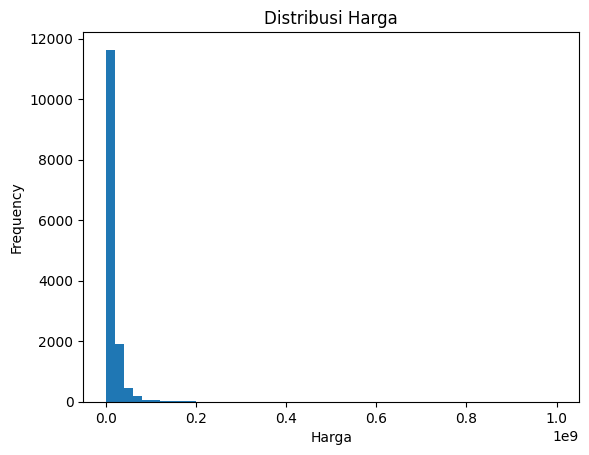

In [6]:
# Ringkasan statistik
display(df["harga"].describe())

# Distribusi (histogram)
import matplotlib.pyplot as plt
df["harga"].plot(kind="hist", bins=50, title="Distribusi Harga")
plt.xlabel("Harga")
plt.show()

In [7]:
df[["kamar_tidur", "luas", "jumlah_foto", "lintang"]].head(10)

,kamar_tidur,luas,jumlah_foto,lintang
0,2,145.5,8 photos,30.03
1,2,97.3 m2,12,27.13
2,2,139.1 m2,14,30.07
3,NaN,--,9,30.04
4,3,171.5,11,29.99
5,NaN,NaN,12,30.01
6,3,110.9,17,27.18
7,4,?,11,30.16
8,4 bedrooms,272.9 sqm,9.0,30.07
9,4,245.0,15,30.05


In [8]:
drop_cols = [
    "id", "kode_listing", "nomor_rera", "id_broker",
    "nama_agen", "nama_broker",
    "email_agen", "email_broker", "email_kontak",
    "telepon_broker", "telepon_kontak", "whatsapp_kontak",
    "judul", "lokasi_lengkap", "fasilitas", "tanggal_listing"
]

df_clean = df.drop(columns=drop_cols)

In [9]:
num_cols = ["kamar_tidur", "kamar_mandi", "luas",
            "jumlah_foto", "lintang", "bujur"]
for c in num_cols:
    df_clean[c] = pd.to_numeric(df_clean[c], errors="coerce")

In [10]:
import numpy as np
import pandas as pd

# Pastikan dataframe hasil drop sudah disalin
df_clean = df_clean.copy()

# 1. Cleaning kolom 'luas' (mengambil angka, mengabaikan 'm2', 'sqm', '?', '--')
# Regex ini akan mengambil angka desimal (misal: 145.5)
df_clean["luas"] = df_clean["luas"].astype(str).str.extract(r'(\d+\.?\d*)')[0]
df_clean["luas"] = pd.to_numeric(df_clean["luas"], errors="coerce")

# 2. Cleaning kolom 'jumlah_foto' (mengambil angka, mengabaikan 'photos')
df_clean["jumlah_foto"] = df_clean["jumlah_foto"].astype(str).str.extract(r'(\d+)')[0]
df_clean["jumlah_foto"] = pd.to_numeric(df_clean["jumlah_foto"], errors="coerce")

# 3. Cleaning kolom 'kamar_tidur' dan 'kamar_mandi' (mengabaikan 'bedrooms', 'Missing value')
df_clean["kamar_tidur"] = df_clean["kamar_tidur"].astype(str).str.extract(r'(\d+)')[0]
df_clean["kamar_tidur"] = pd.to_numeric(df_clean["kamar_tidur"], errors="coerce")

df_clean["kamar_mandi"] = df_clean["kamar_mandi"].astype(str).str.extract(r'(\d+)')[0]
df_clean["kamar_mandi"] = pd.to_numeric(df_clean["kamar_mandi"], errors="coerce")

# 4. Cleaning lintang dan bujur (karena mungkin sudah angka, tapi pastikan)
df_clean["lintang"] = pd.to_numeric(df_clean["lintang"], errors="coerce")
df_clean["bujur"] = pd.to_numeric(df_clean["bujur"], errors="coerce")

# Cek hasilnya
print(df_clean[["kamar_tidur", "luas", "jumlah_foto", "lintang"]].head(10))
print("\nJumlah missing value setelah cleaning:")
print(df_clean[["kamar_tidur", "luas", "jumlah_foto", "lintang"]].isna().sum())

   kamar_tidur   luas  jumlah_foto  lintang
0          2.0  145.5          NaN    30.03
1          2.0    NaN         12.0    27.13
2          2.0    NaN         14.0    30.07
3          NaN    NaN          9.0    30.04
4          3.0  171.5         11.0    29.99
5          NaN    NaN         12.0    30.01
6          3.0  110.9         17.0    27.18
7          4.0    NaN         11.0    30.16
8          NaN    NaN          9.0    30.07
9          4.0  245.0         15.0    30.05

Jumlah missing value setelah cleaning:
kamar_tidur    4289
luas           6549
jumlah_foto    3525
lintang        3043
dtype: int64


In [11]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14416 entries, 0 to 14415
Data columns (total 29 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   kategori            14416 non-null  object 
 1   jenis_listing       14416 non-null  object 
 2   jenis_penawaran     14416 non-null  object 
 3   periode_harga       14416 non-null  object 
 4   mata_uang           14416 non-null  object 
 5   satuan_luas         14416 non-null  object 
 6   eksklusif           14416 non-null  object 
 7   kota                13871 non-null  object 
 8   area_kota           13860 non-null  object 
 9   distrik             13396 non-null  object 
 10  subdistrik          12318 non-null  object 
 11  lintang             11373 non-null  float64
 12  bujur               11285 non-null  float64
 13  tipe_properti       14416 non-null  object 
 14  kamar_tidur         10127 non-null  float64
 15  kamar_mandi         10240 non-null  float64
 16  luas

count    1.441600e+04
mean     1.579055e+07
std      3.343107e+07
min      1.131160e+05
25%      5.250000e+06
50%      9.055500e+06
75%      1.700000e+07
max      1.000000e+09
Name: harga, dtype: float64

Skewness: 17.156581720218608


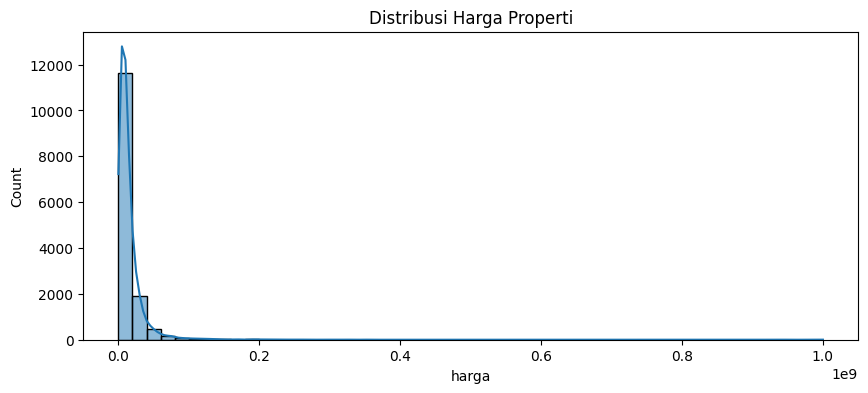

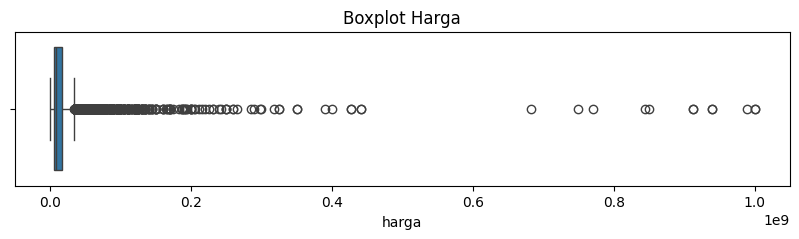

In [12]:
display(df_clean["harga"].describe())
print("Skewness:", df_clean["harga"].skew())

plt.figure(figsize=(10, 4))
sns.histplot(df_clean["harga"], bins=50, kde=True)
plt.title("Distribusi Harga Properti")
plt.show()

plt.figure(figsize=(10, 2))
sns.boxplot(x=df_clean["harga"])
plt.title("Boxplot Harga")
plt.show()

In [13]:
df_clean["harga_log"] = np.log1p(df_clean["harga"])

print(f"Skewness : {df_clean['harga_log'].skew():.4f}")
print(f"Kurtosis : {df_clean['harga_log'].kurt():.4f}")
print(df_clean['harga_log'].describe())

Skewness : 0.0784
Kurtosis : 1.0975
count    14416.000000
mean        16.060483
std          0.954075
min         11.636178
25%         15.473739
50%         16.018883
75%         16.648724
max         20.723266
Name: harga_log, dtype: float64


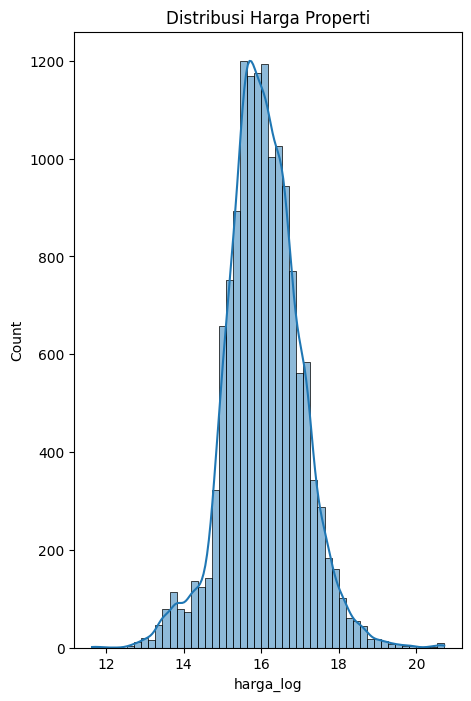

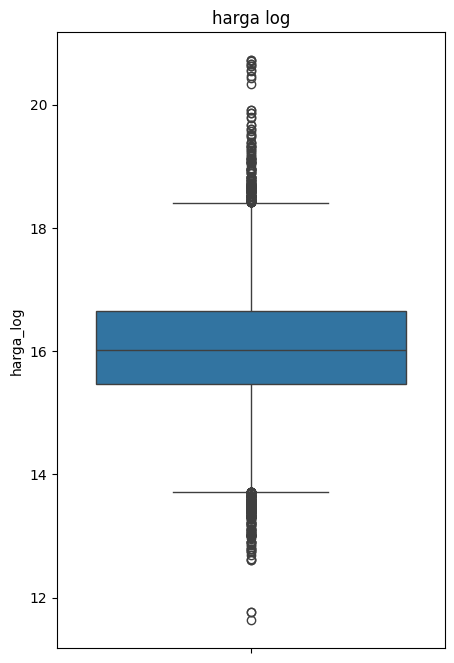

In [14]:
plt.figure(figsize=(5,8))
sns.histplot(data=df_clean["harga_log"], bins=50, kde=True)
plt.title("Distribusi Harga Properti")
plt.show()

plt.figure(figsize=(5,8))
sns.boxplot(data=df_clean["harga_log"])
plt.title("harga log")
plt.show()

In [15]:
print((df_clean["harga"] <= 0).sum())

0


In [16]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14416 entries, 0 to 14415
Data columns (total 30 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   kategori            14416 non-null  object 
 1   jenis_listing       14416 non-null  object 
 2   jenis_penawaran     14416 non-null  object 
 3   periode_harga       14416 non-null  object 
 4   mata_uang           14416 non-null  object 
 5   satuan_luas         14416 non-null  object 
 6   eksklusif           14416 non-null  object 
 7   kota                13871 non-null  object 
 8   area_kota           13860 non-null  object 
 9   distrik             13396 non-null  object 
 10  subdistrik          12318 non-null  object 
 11  lintang             11373 non-null  float64
 12  bujur               11285 non-null  float64
 13  tipe_properti       14416 non-null  object 
 14  kamar_tidur         10127 non-null  float64
 15  kamar_mandi         10240 non-null  float64
 16  luas

In [17]:
for c in ["lintang", "bujur"]:
    df_clean[c] = df_clean[c].fillna(df_clean[c].median())

In [18]:
num_impute = ["kamar_tidur", "kamar_mandi", "jumlah_foto"]
for c in num_impute:
    df_clean[c] = df_clean[c].fillna(df_clean[c].median())

In [19]:
cat_impute = ["kota", "area_kota", "distrik", "subdistrik",
              "perabot", "status_pembangunan", "metode_pembayaran"]
for c in cat_impute:
    df_clean[c] = df_clean[c].fillna("Unknown")

In [20]:
for c in df_clean.select_dtypes(include="object").columns:
    df_clean[c] = df_clean[c].fillna("Unknown")

In [21]:
print(df_clean["mata_uang"].value_counts())
print(df_clean["satuan_luas"].value_counts())
print(df_clean["periode_harga"].value_counts())

mata_uang
EGP    14416
Name: count, dtype: int64
satuan_luas
sqm    14416
Name: count, dtype: int64
periode_harga
sell    14416
Name: count, dtype: int64


In [22]:
df_clean["luas"] = df_clean["luas"].astype(str).str.extract(r'(\d+\.?\d*)')[0]
df_clean["luas"] = pd.to_numeric(df_clean["luas"], errors="coerce")
df_clean["luas"] = df_clean["luas"].fillna(df_clean["luas"].median())  # imputasi setelahnya

In [23]:
from sklearn.preprocessing import LabelEncoder

cat_cols = df_clean.select_dtypes(include="object").columns.tolist()
print(f"Kolom yang perlu di-encode: {len(cat_cols)}")
print(cat_cols)

# Opsi 1: One-Hot (kalau cardinality rendah)
df_encoded = pd.get_dummies(df_clean, columns=cat_cols, drop_first=True)

# Opsi 2: Label Encoding (kalau cardinality tinggi, mis. kota/distrik)
# le = LabelEncoder()
# for c in cat_cols:
#     df_clean[c] = le.fit_transform(df_clean[c].astype(str))

Kolom yang perlu di-encode: 22
['kategori', 'jenis_listing', 'jenis_penawaran', 'periode_harga', 'mata_uang', 'satuan_luas', 'eksklusif', 'kota', 'area_kota', 'distrik', 'subdistrik', 'tipe_properti', 'perabot', 'status_pembangunan', 'level_listing', 'premium', 'terverifikasi', 'unggulan', 'bangunan_baru', 'langsung_developer', 'ada_tampilan_360', 'metode_pembayaran']


In [24]:
for c in cat_cols:
    print(f"{c}: {df_clean[c].nunique()} unique")

kategori: 1 unique
jenis_listing: 1 unique
jenis_penawaran: 1 unique
periode_harga: 1 unique
mata_uang: 1 unique
satuan_luas: 1 unique
eksklusif: 3 unique
kota: 36 unique
area_kota: 146 unique
distrik: 685 unique
subdistrik: 1160 unique
tipe_properti: 90 unique
perabot: 13 unique
status_pembangunan: 63 unique
level_listing: 9 unique
premium: 6 unique
terverifikasi: 3 unique
unggulan: 6 unique
bangunan_baru: 3 unique
langsung_developer: 3 unique
ada_tampilan_360: 6 unique
metode_pembayaran: 13 unique


In [25]:
display(df_clean.isna().sum().sum())

np.int64(0)

In [26]:
missing = df_clean.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)
print(f"\nTotal: {missing.sum()}")

Series([], dtype: int64)

Total: 0


In [27]:
constant_cols = [
    "kategori", "jenis_listing", "jenis_penawaran",
    "periode_harga", "mata_uang", "satuan_luas"
]
df_clean = df_clean.drop(columns=constant_cols)
print("Shape setelah drop konstan:", df_clean.shape)

Shape setelah drop konstan: (14416, 24)


In [28]:
# 1. One-Hot untuk cardinality rendah
onehot_cols = [
    "eksklusif", "terverifikasi", "bangunan_baru", "langsung_developer",
    "premium", "unggulan", "ada_tampilan_360", "level_listing",
    "perabot", "metode_pembayaran", "kota"
]
df_encoded = pd.get_dummies(df_clean, columns=onehot_cols,
                             drop_first=True, dtype=int)

# 2. Frequency Encoding untuk cardinality sedang-tinggi
freq_cols = ["status_pembangunan", "tipe_properti", "area_kota", "distrik"]
for c in freq_cols:
    freq = df_clean[c].value_counts(normalize=True)
    df_encoded[c + "_freq"] = df_clean[c].map(freq)
df_encoded = df_encoded.drop(columns=freq_cols)

# 3. Subdistrik: DROP (terlalu granular, 1160 unique)
df_encoded = df_encoded.drop(columns=["subdistrik"])

print("Shape final:", df_encoded.shape)
print("Missing:", df_encoded.isna().sum().sum())

Shape final: (14416, 102)
Missing: 0


In [29]:
print("Shape:", df_encoded.shape)
print("Missing:", df_encoded.isna().sum().sum())
print("Duplikat:", df_encoded.duplicated().sum())

Shape: (14416, 102)
Missing: 0
Duplikat: 554


In [30]:
df_encoded = df_encoded.drop_duplicates().reset_index(drop=True)
print("Shape setelah drop duplikat:", df_encoded.shape)

Shape setelah drop duplikat: (13862, 102)


In [31]:
# y = df_encoded["harga_log"]
# X = df_encoded.drop(columns=["harga", "harga_log"])

# print("Shape X:", X.shape)
# print("Shape y:", y.shape)

In [32]:
# import numpy as np
# from sklearn.model_selection import train_test_split

# # Pastikan tidak ada inf / NaN di X
# print("NaN di X:", X.isna().sum().sum())
# print("Inf di X:", np.isinf(X.select_dtypes(include=np.number)).sum().sum())

# # Split 80/20
# X_train, X_test, y_train, y_test = train_test_split(
#     X, y, test_size=0.2, random_state=42
# )

# print("Train:", X_train.shape, "| Test:", X_test.shape)
# print(f"\nSkewness y_train: {y_train.skew():.4f}")
# print(f"Skewness y_test : {y_test.skew():.4f}")

In [33]:
# model = TransformedTargetRegressor(
#     regressor=LinearRegression(),
#     func=np.log1p,
#     inverse_func=np.expm1
# )

In [34]:
# Pastikan harga asli TIDAK ada di fitur (data leakage!)
y = df_encoded["harga_log"]                          # target (skala log)
X = df_encoded.drop(columns=["harga", "harga_log"])  # fitur

# Split (kalau belum, ulangi di sini biar konsisten)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Simpan y_test dalam skala asli untuk evaluasi akhir
y_test_asli = np.expm1(y_test)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

X_train: (11089, 100) | X_test: (2773, 100)
y_train: (11089,) | y_test: (2773,)


In [35]:
def evaluate_model(name, y_true_log, y_pred_log):
    """Evaluasi di skala log DAN skala rupiah asli."""
    # Skala log
    mae_log  = mean_absolute_error(y_true_log, y_pred_log)
    rmse_log = np.sqrt(mean_squared_error(y_true_log, y_pred_log))
    r2       = r2_score(y_true_log, y_pred_log)

    # Skala asli (rupiah)
    y_true_asli = np.expm1(y_true_log)
    y_pred_asli = np.expm1(y_pred_log)
    mae_asli    = mean_absolute_error(y_true_asli, y_pred_asli)
    rmse_asli   = np.sqrt(mean_squared_error(y_true_asli, y_pred_asli))

    print(f"\n{'='*50}")
    print(f"  {name}")
    print(f"{'='*50}")
    print(f"  [Skala Log]")
    print(f"    MAE  : {mae_log:.4f}")
    print(f"    RMSE : {rmse_log:.4f}")
    print(f"    R²   : {r2:.4f}")
    print(f"  [Skala Rupiah]")
    print(f"    MAE  : Rp {mae_asli:,.0f}")
    print(f"    RMSE : Rp {rmse_asli:,.0f}")

    return {"model": name, "MAE_log": mae_log, "RMSE_log": rmse_log,
            "R2": r2, "MAE_rp": mae_asli, "RMSE_rp": rmse_asli}

In [36]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

lr_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])
lr_pipe.fit(X_train, y_train)
y_pred_lr = lr_pipe.predict(X_test)

res_lr = evaluate_model("Linear Regression", y_test, y_pred_lr)


  Linear Regression
  [Skala Log]
    MAE  : 0.5819
    RMSE : 1.3872
    R²   : -0.9781
  [Skala Rupiah]
    MAE  : Rp 1,427,571,433,864,340,048,667,738,112
    RMSE : Rp 75,174,886,802,289,526,707,691,978,752


In [37]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_split=5,
    n_jobs=-1,
    random_state=42
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

res_rf = evaluate_model("Random Forest", y_test, y_pred_rf)


  Random Forest
  [Skala Log]
    MAE  : 0.3929
    RMSE : 0.5659
    R²   : 0.6708
  [Skala Rupiah]
    MAE  : Rp 7,792,571
    RMSE : Rp 42,754,284


In [38]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)

res_xgb = evaluate_model("XGBoost", y_test, y_pred_xgb)


  XGBoost
  [Skala Log]
    MAE  : 0.3708
    RMSE : 0.5283
    R²   : 0.7131
  [Skala Rupiah]
    MAE  : Rp 7,627,602
    RMSE : Rp 43,163,494


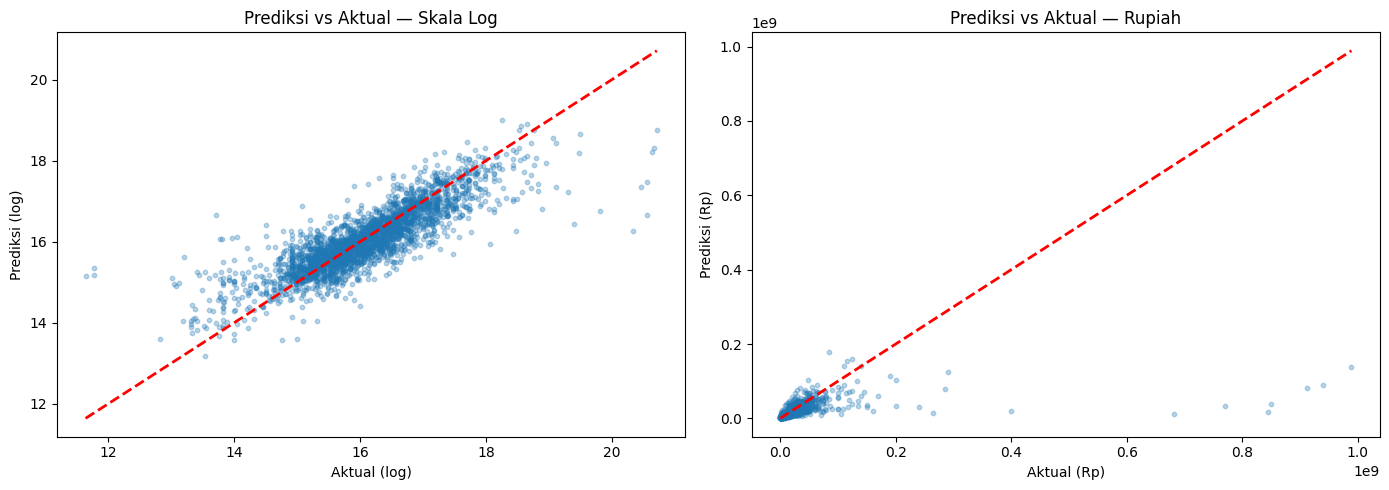

In [39]:
import matplotlib.pyplot as plt

best_pred = y_pred_xgb  # ganti dengan model terbaik

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Skala log
axes[0].scatter(y_test, best_pred, alpha=0.3, s=10)
axes[0].plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()], "r--", lw=2)
axes[0].set_xlabel("Aktual (log)")
axes[0].set_ylabel("Prediksi (log)")
axes[0].set_title("Prediksi vs Aktual — Skala Log")

# Skala rupiah
axes[1].scatter(np.expm1(y_test), np.expm1(best_pred), alpha=0.3, s=10)
lim = [np.expm1(y_test).min(), np.expm1(y_test).max()]
axes[1].plot(lim, lim, "r--", lw=2)
axes[1].set_xlabel("Aktual (Rp)")
axes[1].set_ylabel("Prediksi (Rp)")
axes[1].set_title("Prediksi vs Aktual — Rupiah")

plt.tight_layout()
plt.show()

/tmp/ipykernel_110128/1163869015.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_imp, y="Fitur", x="Importance", palette="viridis")


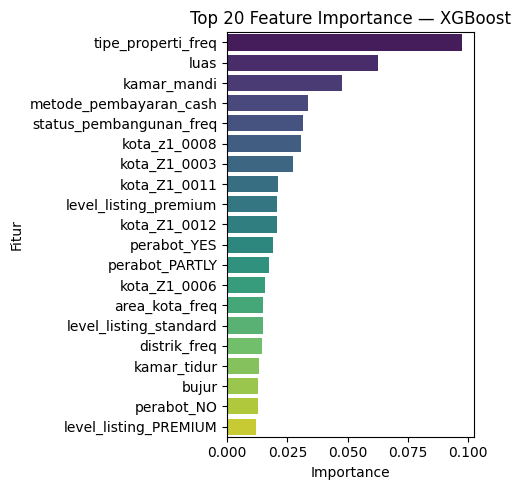

In [40]:
import seaborn as sns

feat_imp = pd.DataFrame({
    "Fitur": X_train.columns,
    "Importance": xgb.feature_importances_
}).sort_values("Importance", ascending=False).head(20)

plt.figure(figsize=(5, 5))
sns.barplot(data=feat_imp, y="Fitur", x="Importance", palette="viridis")
plt.title("Top 20 Feature Importance — XGBoost")
plt.tight_layout()
plt.show()

In [41]:
hasil = pd.DataFrame([res_lr, res_rf, res_xgb]).sort_values("RMSE_log")
display(hasil)

# MAPE untuk model terbaik
from sklearn.metrics import mean_absolute_percentage_error
mape = mean_absolute_percentage_error(np.expm1(y_test), np.expm1(y_pred_xgb))
print(f"MAPE XGBoost: {mape*100:.2f}%")

,model,MAE_log,RMSE_log,R2,MAE_rp,RMSE_rp
2,XGBoost,0.370828,0.528298,0.713085,7.627602e+06,4.316349e+07
1,Random Forest,0.392892,0.565858,0.670837,7.792571e+06,4.275428e+07
0,Linear Regression,0.581904,1.387175,-0.978145,1.427571e+27,7.517489e+28


MAPE XGBoost: 44.11%


In [42]:
import numpy as np
import pandas as pd
from xgboost import XGBRegressor

# Copy dulu biar aman
X_train_fe = X_train.copy()
X_test_fe  = X_test.copy()

for df_ in [X_train_fe, X_test_fe]:
    # Rasio & interaksi yang masuk akal secara bisnis
    df_["rasio_km_kt"]    = df_["kamar_mandi"] / (df_["kamar_tidur"] + 1)
    df_["luas_per_kamar"] = df_["luas"] / (df_["kamar_tidur"] + 1)
    df_["total_kamar"]    = df_["kamar_tidur"] + df_["kamar_mandi"]
    df_["luas_x_km"]      = df_["luas"] * df_["kamar_mandi"]
    df_["log_luas"]       = np.log1p(df_["luas"])       # luas juga skewed
    df_["log_foto"]       = np.log1p(df_["jumlah_foto"])

xgb_fe = XGBRegressor(
    n_estimators=500, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.8,
    random_state=42, n_jobs=-1
)
xgb_fe.fit(X_train_fe, y_train)
y_pred_fe = xgb_fe.predict(X_test_fe)

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
print(f"R²   : {r2_score(y_test, y_pred_fe):.4f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test, y_pred_fe)):.4f}")

R²   : 0.7162
RMSE : 0.5255


In [43]:
import numpy as np
import pandas as pd

df_sub = df_test.copy()

# === 1. Simpan id ===
id_submission = df_sub["id"].copy()

# === 2. Drop kolom yang sama seperti training ===
drop_cols = [
    "id", "kode_listing", "nomor_rera", "id_broker",
    "nama_agen", "nama_broker",
    "email_agen", "email_broker", "email_kontak",
    "telepon_broker", "telepon_kontak", "whatsapp_kontak",
    "judul", "lokasi_lengkap", "fasilitas",
]
df_sub = df_sub.drop(columns=[c for c in drop_cols if c in df_sub.columns])

# === 3. Regex extract numerik ===
df_sub["luas"] = df_sub["luas"].astype(str).str.extract(r'(\d+\.?\d*)')[0]
df_sub["luas"] = pd.to_numeric(df_sub["luas"], errors="coerce")

df_sub["jumlah_foto"] = df_sub["jumlah_foto"].astype(str).str.extract(r'(\d+)')[0]
df_sub["jumlah_foto"] = pd.to_numeric(df_sub["jumlah_foto"], errors="coerce")

for c in ["kamar_tidur", "kamar_mandi"]:
    df_sub[c] = df_sub[c].astype(str).str.extract(r'(\d+)')[0]
    df_sub[c] = pd.to_numeric(df_sub[c], errors="coerce")

for c in ["lintang", "bujur"]:
    df_sub[c] = pd.to_numeric(df_sub[c], errors="coerce")

# === 4. Drop tanggal_listing ===
df_sub = df_sub.drop(columns=[c for c in ["tanggal_listing"] if c in df_sub.columns])

# === 5. Imputasi numerik (pakai median dari TRAIN, bukan test!) ===
num_cols = ["luas", "jumlah_foto", "kamar_tidur", "kamar_mandi", "lintang", "bujur"]
for c in num_cols:
    if c in df_sub.columns:
        median_val = X_train[c].median() if c in X_train.columns else df_sub[c].median()
        df_sub[c] = df_sub[c].fillna(median_val)

# === 6. Imputasi kategorikal ===
for c in df_sub.select_dtypes(include="object").columns:
    df_sub[c] = df_sub[c].fillna("Unknown")

# === 7. Drop kolom konstan ===
const_cols = ["kategori", "jenis_listing", "jenis_penawaran",
              "periode_harga", "mata_uang", "satuan_luas"]
df_sub = df_sub.drop(columns=[c for c in const_cols if c in df_sub.columns])

# === 8. Encoding — PENTING: align dengan training ===
onehot_cols = ["eksklusif", "terverifikasi", "bangunan_baru", "langsung_developer",
               "premium", "unggulan", "ada_tampilan_360", "level_listing",
               "perabot", "metode_pembayaran", "kota"]
onehot_cols = [c for c in onehot_cols if c in df_sub.columns]
df_sub = pd.get_dummies(df_sub, columns=onehot_cols, drop_first=True, dtype=int)

# Freq encoding
freq_cols = ["status_pembangunan", "tipe_properti", "area_kota", "distrik"]
for c in freq_cols:
    if c in df_sub.columns:
        freq = df_sub[c].value_counts(normalize=True)  # ⚠️ ideal dari train
        df_sub[c + "_freq"] = df_sub[c].map(freq)
        df_sub = df_sub.drop(columns=[c])

if "subdistrik" in df_sub.columns:
    df_sub = df_sub.drop(columns=["subdistrik"])

# === 9. Align kolom dengan X_train (WAJIB) ===
df_sub = df_sub.reindex(columns=X_train.columns, fill_value=0)

# === 10. Feature Engineering (sama seperti training) ===
df_sub["rasio_km_kt"]    = df_sub["kamar_mandi"] / (df_sub["kamar_tidur"] + 1)
df_sub["luas_per_kamar"] = df_sub["luas"] / (df_sub["kamar_tidur"] + 1)
df_sub["total_kamar"]    = df_sub["kamar_tidur"] + df_sub["kamar_mandi"]
df_sub["luas_x_km"]      = df_sub["luas"] * df_sub["kamar_mandi"]
df_sub["log_luas"]       = np.log1p(df_sub["luas"])
df_sub["log_foto"]       = np.log1p(df_sub["jumlah_foto"])

# Pastikan urutan kolom sama dengan X_train_fe
df_sub = df_sub[X_train_fe.columns]

print("Shape final df_sub:", df_sub.shape)
print("Missing:", df_sub.isna().sum().sum())

Shape final df_sub: (5940, 106)
Missing: 0


In [44]:
from sklearn.model_selection import KFold, cross_val_score
from xgboost import XGBRegressor
import numpy as np

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(
    XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6,
                 random_state=42, n_jobs=-1),
    X_train_fe, y_train,
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1
)
print(f"CV RMSE: {-scores.mean():.4f} ± {scores.std():.4f}")

CV RMSE: 0.5430 ± 0.0066


In [45]:
X_train_safe = X_train_fe.copy()
X_test_safe  = X_test_fe.copy()
X_train_safe.columns = [f"f{i}" for i in range(X_train_fe.shape[1])]
X_test_safe.columns  = [f"f{i}" for i in range(X_test_fe.shape[1])]

from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

lgbm = LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=63,
                      random_state=42, n_jobs=-1, verbose=-1)
lgbm.fit(X_train_safe, y_train)
print("LGBM R²:", r2_score(y_test, lgbm.predict(X_test_safe)))

cat = CatBoostRegressor(iterations=500, learning_rate=0.05, depth=6,
                         random_seed=42, verbose=0)
cat.fit(X_train_safe, y_train)
print("CatBoost R²:", r2_score(y_test, cat.predict(X_test_safe)))

LGBM R²: 0.7165740221225966
CatBoost R²: 0.6885556929817783


In [46]:
# Prediksi (skala log)
y_pred_log = xgb_fe.predict(df_sub)

# Inverse transform ke rupiah
y_pred_rp = np.expm1(y_pred_log)

# Buat submission
submission = pd.DataFrame({
    "id": id_submission.values,
    "harga": y_pred_rp
})

# Cek hasil
print("Shape submission:", submission.shape)
print("\nStatistik prediksi harga:")
print(submission["harga"].describe())

print("\nPreview submission:")
display(submission.head(10))

Shape submission: (5940, 2)

Statistik prediksi harga:
count    5.940000e+03
mean     1.211302e+07
std      8.956817e+06
min      6.770202e+05
25%      6.954497e+06
50%      1.026707e+07
75%      1.524747e+07
max      1.497086e+08
Name: harga, dtype: float64

Preview submission:


,id,harga
0,14417,1.070182e+07
1,14418,1.504481e+06
2,14419,1.083134e+07
3,14420,1.084597e+07
4,14421,5.940836e+06
5,14422,1.014473e+07
6,14423,1.415348e+07
7,14424,1.710583e+07
8,14425,9.462444e+06
9,14426,2.041109e+07


In [47]:
submission.to_csv("submission.csv", index=False)
print("✅ submission.csv berhasil disimpan!")

✅ submission.csv berhasil disimpan!


In [48]:
import numpy as np
from sklearn.metrics import r2_score, mean_squared_error

# Prediksi dari semua model yang sudah di-fit
pred_xgb_fe = xgb_fe.predict(X_test_fe)
pred_lgbm   = lgbm.predict(X_test_safe)
pred_rf     = rf.predict(X_test)
pred_cat    = cat.predict(X_test_safe)

# Uji beberapa kombinasi bobot
kombinasi = {
    "50/50 XGB+LGBM"          : 0.5*pred_xgb_fe + 0.5*pred_lgbm,
    "60/40 XGB+LGBM"          : 0.6*pred_xgb_fe + 0.4*pred_lgbm,
    "40/40/20 XGB+LGBM+RF"    : 0.4*pred_xgb_fe + 0.4*pred_lgbm + 0.2*pred_rf,
    "35/35/15/15 all"         : 0.35*pred_xgb_fe + 0.35*pred_lgbm + 0.15*pred_rf + 0.15*pred_cat,
    "40/35/15/10 all"         : 0.40*pred_xgb_fe + 0.35*pred_lgbm + 0.15*pred_rf + 0.10*pred_cat,
}

print(f"{'Kombinasi':<28} | R²      | RMSE")
print("-" * 55)
hasil = []
for nama, pred in kombinasi.items():
    r2 = r2_score(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    hasil.append({"nama": nama, "r2": r2, "rmse": rmse, "pred": pred})
    print(f"{nama:<28} | {r2:.4f}  | {rmse:.4f}")

# Ambil yang terbaik
best = max(hasil, key=lambda x: x["r2"])
print(f"\n🏆 Best: {best['nama']} dengan R² = {best['r2']:.4f}")

Kombinasi                    | R²      | RMSE
-------------------------------------------------------
50/50 XGB+LGBM               | 0.7212  | 0.5208
60/40 XGB+LGBM               | 0.7210  | 0.5210
40/40/20 XGB+LGBM+RF         | 0.7195  | 0.5223
35/35/15/15 all              | 0.7187  | 0.5231
40/35/15/10 all              | 0.7193  | 0.5226

🏆 Best: 50/50 XGB+LGBM dengan R² = 0.7212


In [49]:
from sklearn.metrics import mean_absolute_percentage_error, mean_absolute_error

# Pakai model terbaik dari Langkah 1
best_pred_log = best["pred"]

y_pred_rp = np.expm1(best_pred_log)
y_true_rp = np.expm1(y_test)

print(f"R² (log) : {best['r2']:.4f}")
print(f"RMSE(log): {best['rmse']:.4f}")
print(f"MAE (Rp) : Rp {mean_absolute_error(y_true_rp, y_pred_rp):,.0f}")
print(f"RMSE(Rp) : Rp {np.sqrt(mean_squared_error(y_true_rp, y_pred_rp)):,.0f}")
print(f"MAPE     : {mean_absolute_percentage_error(y_true_rp, y_pred_rp)*100:.2f}%")

R² (log) : 0.7212
RMSE(log): 0.5208
MAE (Rp) : Rp 7,425,871
RMSE(Rp) : Rp 42,426,034
MAPE     : 43.72%


In [51]:
import pandas as pd
df_sub_renamed = df_sub.copy()

df_sub_renamed.columns = [f"f{i}" for i in range(df_sub.shape[1])]

print("Shape df_sub_renamed :", df_sub_renamed.shape)
print("Shape X_train_safe   :", X_train_safe.shape)
print("Kolom cocok?", df_sub_renamed.shape[1] == X_train_safe.shape[1])

pred_test_xgb_fe = xgb_fe.predict(df_sub)
pred_test_lgbm   = lgbm.predict(df_sub_renamed)      # yang kolomnya f0, f1, ...
#pred_test_rf     = rf.predict(df_sub)
pred_test_cat    = cat.predict(df_sub_renamed)

y_test_pred_log = (0.5 * pred_test_xgb_fe + 0.5 * pred_test_lgbm)

y_test_pred_rp = np.expm1(y_test_pred_log)

submission_v2 = pd.DataFrame({
    "id": id_submission.values,
    "harga": y_test_pred_rp
})

submission_v2.to_csv("submission_v2.csv", index=False)
print("✅ submission_v2.csv tersimpan!")
print(submission_v2.head())

Shape df_sub_renamed : (5940, 106)
Shape X_train_safe   : (11089, 106)
Kolom cocok? True
✅ submission_v2.csv tersimpan!
      id         harga
0  14417  9.389472e+06
1  14418  1.390080e+06
2  14419  1.277059e+07
3  14420  8.157829e+06
4  14421  5.623642e+06
